# Newton and Quasi-Newton Methods

**Seong Cho** · ACME Volume 2, Lab 12

**Lab objective:** implement Newton's method, BFGS (a variant that numerically approximates the Hessian, trading some convergence speed for lower cost), and the Gauss-Newton method for nonlinear least squares problems.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import sys
import numpy as np
import scipy.linalg as la
from scipy.optimize import *
import matplotlib.pyplot as plt
import time

## Newton's Method

For $g : \mathbb{R} \to \mathbb{R}$, Newton's method finds a root $\bar{x}$ of $g(x) = 0$ with the rule

$$x_{k+1} = x_k - \frac{g(x_k)}{g'(x_k)}. \tag{12.1}$$

Substituting $g = f'$ for $f : \mathbb{R} \to \mathbb{R}$ gives an iterative method for locating a critical point $x^*$ of $f$ satisfying $f'(x^*) = 0$:

$$x_{k+1} = x_k - \frac{f'(x_k)}{f''(x_k)}. \tag{12.2}$$

This generalizes to higher dimensions. For $g : \mathbb{R}^n \to \mathbb{R}^n$, the iteration

$$\mathbf{x}_{k+1} = \mathbf{x}_k - Dg(\mathbf{x}_k)^{-1}g(\mathbf{x}_k) \tag{12.3}$$

finds $\bar{\mathbf{x}}$ such that $g(\bar{\mathbf{x}}) = \mathbf{0}$. For $f : \mathbb{R}^n \to \mathbb{R}$, plugging $g = Df$ into (12.3) gives an iteration for an optimal value $\mathbf{x}^*$ satisfying $Df(\mathbf{x}^*) = \mathbf{0}$:

$$\mathbf{x}_{k+1} = \mathbf{x}_k - D^2f(\mathbf{x}_k)^{-1}Df(\mathbf{x}_k)^\mathsf{T}. \tag{12.4}$$

Here the first derivative $Df : \mathbb{R}^n \to \mathbb{R}^n$ evaluates to the row vector $Df(\mathbf{x}) = [D_1f(\mathbf{x}) \ \cdots \ D_nf(\mathbf{x})]$, and the second derivative $D^2f : \mathbb{R}^n \to \mathbb{R}^{n \times n}$ evaluates to the $n \times n$ Hessian matrix

$$D^2f(\mathbf{x}) = \begin{bmatrix} D_1D_1f(\mathbf{x}) & \cdots & D_nD_1f(\mathbf{x}) \\ \vdots & & \vdots \\ D_1D_nf(\mathbf{x}) & \cdots & D_nD_nf(\mathbf{x}) \end{bmatrix} = \begin{bmatrix} \frac{\partial^2 f}{\partial x_1\partial x_1} & \cdots & \frac{\partial^2 f}{\partial x_n\partial x_1} \\ \vdots & \ddots & \vdots \\ \frac{\partial^2 f}{\partial x_1\partial x_n} & \cdots & \frac{\partial^2 f}{\partial x_n\partial x_n} \end{bmatrix}.$$

## Problem 1: Newton's method

> **Problem 1.** Write a function that accepts functions $Df : \mathbb{R}^n \to \mathbb{R}^n$ and $D^2f : \mathbb{R}^n \to \mathbb{R}^{n \times n}$, a starting point $\mathbf{x}_0 \in \mathbb{R}^n$, an integer `maxiter`, and a stopping tolerance `tol`. Use Newton's method in (12.4) to optimize $f$. Return the final estimate $\mathbf{x}_k$, whether or not the method converged (`True` or `False`), and the number of iterations computed.
>
> Your implementation should include the following items.
> - Iterate until either $\|Df(\mathbf{x}_k)\|_\infty <$ `tol` or $k >$ `maxiter`. The criteria $\|\mathbf{x}_k - \mathbf{x}_{k-1}\| <$ `tol` is also common, but making sure $Df$ is near zero works better in many circumstances.
> - Instead of inverting $D^2f(\mathbf{x}_k)$ at each step, solve the equation $D^2f(\mathbf{x}_k)\mathbf{z}_k = Df(\mathbf{x}_k)^\mathsf{T}$ and compute $\mathbf{x}_{k+1} = \mathbf{x}_k - \mathbf{z}_k$. In other words, use `la.solve()` instead of `la.inv()`.
> - Avoid recomputing values by only computing $Df(\mathbf{x}_k)$ and $D^2f(\mathbf{x}_k)$ once for each $k$.
>
> The Rosenbrock function is a common test function for optimization methods.
>
> $$f(x, y) = 100(y - x^2)^2 + (1 - x)^2$$
>
> The minimizer is $\mathbf{x}^* = (1, 1)$ with minimum value $f(1, 1) = 0$. Test your function by minimizing the Rosenbrock function using an initial guess $\mathbf{x}_0 = (-2, 2)$. The function and its derivatives are implemented as `rosen()`, `rosen_der()`, and `rosen_hess()` in `scipy.optimize`. Compare your results to `scipy.optimize.fmin_bfgs()`.

The spec's comparison:

In [2]:
from scipy import optimize as opt
f = opt.rosen               # The Rosenbrock function.
df = opt.rosen_der          # The first derivative.
d2f = opt.rosen_hess        # The second derivative (Hessian).
opt.fmin_bfgs(f=f, x0=[-2,2], fprime=df, maxiter=50)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 35
         Function evaluations: 42
         Gradient evaluations: 42


array([1.00000021, 1.00000045])

The spec printed `array([ 1.00000021, 1.00000045])` with the same convergence message (35 iterations, 42 function and gradient evaluations).

In [3]:
def newton(Df, D2f, x0, maxiter=20, tol=1e-5):
    """Use Newton's method to minimize a function f:R^n -> R.

    Parameters:
        Df (function): The first derivative of f. Accepts and returns a NumPy
            array of shape (n,).
        D2f (function): The second dirivative (Hessian) of f. Accepts a NumPy
            array of shape (n,) and returns a NumPy array of shape (n,n).
        x0 ((n,) ndarray): The initial guess.
        maxiter (int): The maximum number of iterations to compute.
        tol (float): The stopping tolerance.

    Returns:
        ((n,) ndarray): The approximate optimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    # Keep track of convergence and number of iterations
    converged = False
    iterations = 0
    # Loop maxiter number of times before convergence
    for i in range(maxiter):
        iterations += 1
        # Store Df(x0)
        dfx = Df(x0)
        # Equation 12.4, find D2f-1@Df using la.solve
        x1 = x0 - la.solve(D2f(x0), dfx)
        #Condition for convergence
        if la.norm(dfx) < tol:
            converged = True
            break
        # Update x0
        x0 = x1

    return x1, converged, iterations

In [4]:
x, conv, niters = newton(rosen_der, rosen_hess, (-2, 2))
print("newton():", x, conv, niters)
xs = fmin_bfgs(rosen, (-2, 2), fprime=rosen_der, disp=False)
print("fmin_bfgs():", xs)
assert conv and np.allclose(x, [1, 1]) and np.allclose(x, xs, atol=1e-5)

# On a strictly convex quadratic f(x) = x^T Q x / 2 - b^T x, a single Newton step lands on the minimizer Q^{-1} b.
rng = np.random.default_rng(12)
M = rng.normal(size=(4, 4))
Q, b = M @ M.T + 4*np.eye(4), rng.normal(size=4)
xq, conv, niters = newton(lambda x: Q @ x - b, lambda x: Q, np.zeros(4))
print("quadratic:", conv, niters, np.allclose(xq, la.solve(Q, b)))
assert conv and np.allclose(xq, la.solve(Q, b))

newton(): [1. 1.] True 6
fmin_bfgs(): [1.00000021 1.00000045]
quadratic: True 2 True


Newton's method needs 6 iterations from $(-2, 2)$, against 35 for SciPy's BFGS. On the quadratic it takes the exact step first, then stops on the next pass once the gradient there is zero, so it reports 2 iterations.

## BFGS

Newton's method enjoys quadratic convergence when the initial guess is good enough, but computing and inverting the Hessian at each step of (12.4) is often prohibitively expensive. *Quasi-Newton methods* numerically approximate the inverse of the Hessian at each step. They sacrifice some convergence properties in exchange for becoming less computationally expensive, and they make it possible to optimize functions where $D^2f$ is unknown.

*Broyden's method* is a high-dimensional generalization of the secant method: it uses the first derivative to update an approximated Hessian matrix,

$$\mathbf{x}_{k+1} = \mathbf{x}_k - A_k^{-1}Df(\mathbf{x}_k)^\mathsf{T}, \qquad A_{k+1} = A_k + \frac{\mathbf{y}_k - A_k\mathbf{s}_k}{\|\mathbf{s}_k\|^2}\mathbf{s}_k^\mathsf{T}, \tag{12.5}$$

where $\mathbf{s}_k = \mathbf{x}_{k+1} - \mathbf{x}_k$ and $\mathbf{y}_k = Df(\mathbf{x}_{k+1})^\mathsf{T} - Df(\mathbf{x}_k)^\mathsf{T}$. This still involves a matrix inversion; the Sherman-Morrison-Woodbury formula translates the update for $A_k$ into an update for $A_k^{-1}$:

$$A_{k+1}^{-1} = A_k^{-1} + \frac{\mathbf{s}_k - A_k^{-1}\mathbf{y}_k}{\mathbf{s}_k^\mathsf{T}A_k^{-1}\mathbf{y}_k}\left(\mathbf{s}_k^\mathsf{T}A_k^{-1}\right).$$

Unfortunately, even if $D^2f(\mathbf{x}_k)$ is positive definite (which is desirable for minimization), the first-order approximation $A_k$ is not guaranteed to be positive definite, so Broyden's method is unreliable. The *Broyden-Fletcher-Goldfarb-Shanno* (BFGS) method remedies this with the positive definite second-order approximation

$$A_{k+1} = A_k + \frac{\mathbf{y}_k\mathbf{y}_k^\mathsf{T}}{\mathbf{y}_k^\mathsf{T}\mathbf{s}_k} - \frac{A_k\mathbf{s}_k\mathbf{s}_k^\mathsf{T}A_k}{\mathbf{s}_k^\mathsf{T}A_k\mathbf{s}_k}.$$

Applying the Sherman-Morrison-Woodbury formula here as well yields a computationally efficient form of BFGS:

$$\mathbf{x}_{k+1} = \mathbf{x}_k - A_k^{-1}Df(\mathbf{x}_k)^\mathsf{T} \tag{12.6}$$

$$A_{k+1}^{-1} = A_k^{-1} + \frac{(\mathbf{s}_k^\mathsf{T}\mathbf{y}_k + \mathbf{y}_k^\mathsf{T}A_k^{-1}\mathbf{y}_k)\mathbf{s}_k\mathbf{s}_k^\mathsf{T}}{(\mathbf{s}_k^\mathsf{T}\mathbf{y}_k)^2} - \frac{A_k^{-1}\mathbf{y}_k\mathbf{s}_k^\mathsf{T} + \mathbf{s}_k\mathbf{y}_k^\mathsf{T}A_k^{-1}}{\mathbf{s}_k^\mathsf{T}\mathbf{y}_k} \tag{12.7}$$

with $\mathbf{s}_k$ and $\mathbf{y}_k$ as before.

## Problem 2: BFGS

> **Problem 2.** Write a function that accepts a function $Df : \mathbb{R}^n \to \mathbb{R}^n$, a starting point $\mathbf{x}_0 \in \mathbb{R}^n$, an integer `maxiter`, and a stopping tolerance `tol`. Use BFGS as given in (12.6) and (12.7) to optimize $f$, with $A_0^{-1} = I$ (the $n \times n$ identity matrix) as the initial approximation to the inverse of the Hessian. Return the final estimate $\mathbf{x}_k$, whether or not the method converged, and the number of iterations computed.
>
> This method is a little tricky and can have issues if $\mathbf{x}_0$ is chosen poorly. Consider the following as you implement your function.
> - Use the same stopping criteria as in Problem 1, iterating until either $\|Df(\mathbf{x}_k)\|_\infty <$ `tol` or $k >$ `maxiter`. The usual criteria $\|\mathbf{x}_k - \mathbf{x}_{k-1}\| <$ `tol` is not a good choice for BFGS.
> - Avoid recomputing values by only calculating each $Df(\mathbf{x}_k)$, $\mathbf{s}_k$, $\mathbf{y}_k$, and $\mathbf{s}_k^\mathsf{T}\mathbf{y}_k$ once.
> - Note that $\mathbf{s}_k\mathbf{s}_k^\mathsf{T}$, $\mathbf{y}_k\mathbf{s}_k^\mathsf{T}$, and $\mathbf{s}_k\mathbf{y}_k^\mathsf{T}$ are all outer products that result in $n \times n$ matrices. Use `np.outer()` instead of `np.dot()` or the `@` operator for these computations. Carefully identify which parts of (12.7) are scalars and which parts are matrices.
> - If $(\mathbf{s}_k^\mathsf{T}\mathbf{y}_k)^2 = 0$, terminate the iteration early to avoid dividing by zero.
>
> Test your function on the Rosenbrock function as in Problem 1.

In [5]:
def bfgs(Df, x0, maxiter=80, tol=1e-5):
    """Use BFGS to minimize a function f:R^n -> R.

    Parameters:
        Df (function): The first derivative of f. Accepts and returns a NumPy
            array of shape (n,).
        x0 ((n,) ndarray): The initial guess.
        maxiter (int): The maximum number of iterations to compute.
        tol (float): The stopping tolerance.

    Returns:
        ((n,) ndarray): The approximate optimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    # Keep track of convergence and number of iterations
    converged = False
    iterations = 0
    n = len(x0)
    A_inv = np.eye(n)
    dfx = Df(x0)
    # Loop maxiter number of times before convergence
    for i in range(maxiter):
        iterations += 1
        # Equation 12.6
        x1 = x0 - A_inv@dfx
        # Condition for convergence
        if la.norm(dfx) < tol:
            converged = True
            break
        # Store all necessary values for efficiency
        s = x1 - x0
        dfx1 = Df(x1)
        y = dfx1 - dfx
        dfx = dfx1
        sy = np.dot(s,y)
        # Avoid dividing by 0
        if sy == 0:
            break
        # Equation 12.7
        A_inv += ((np.dot(s,y) + np.dot(y, A_inv@y))*np.outer(s,s))/(sy**2) \
                 - (A_inv@np.outer(y,s) + np.outer(s,y)@A_inv)/sy
        # Update x0
        x0 = x1

    return x1, converged, iterations

In [6]:
for m in [150, 300]:
    print(f"maxiter = {m}:", bfgs(rosen_der, (-2, 2), maxiter=m))
x, conv, niters = bfgs(rosen_der, (-2, 2), maxiter=300)
assert conv and np.allclose(x, [1, 1])

# The first few iterates from (-2, 2): without a line search, the early steps are enormous.
for m in range(1, 6):
    print(f"  x_{m} =", bfgs(rosen_der, (-2, 2), maxiter=m)[0])

maxiter = 150: (array([0.86712314, 0.75157046]), False, 150)
maxiter = 300: (array([1., 1.]), True, 164)
  x_1 = [1604.  402.]
  x_2 = [ -1.86782619 427.41122339]
  x_3 = [-2.99784027e+01 -8.97354583e+04]
  x_4 = [-1.99200475 14.58044132]
  x_5 = [-1.99511378  4.24617792]


From $(-2, 2)$ the iteration needs 164 steps on this machine, more than `maxiter=150`. With $A_0^{-1} = I$ and no line search, the first steps throw the iterate out to $|y| \approx 9 \times 10^4$ before it settles into the Rosenbrock valley, so the exact iteration count from this start is sensitive to round-off in those early steps.

Two further checks: BFGS minimizes a strictly convex quadratic, and it agrees with SciPy's `fmin_bfgs()` from random starting points.

In [7]:
xq, conv, niters = bfgs(lambda x: Q @ x - b, np.zeros(4))
print("quadratic:", conv, niters, np.allclose(xq, la.solve(Q, b), atol=1e-5))
assert conv and np.allclose(xq, la.solve(Q, b), atol=1e-5)

np.random.seed(2)
for _ in range(5):
    x0 = np.random.uniform(-3, 3, 2)
    x, conv, niters = bfgs(rosen_der, x0, maxiter=1000)
    print(f"x0 = {np.round(x0, 3)}:  converged = {conv}, iterations = {niters}, x = {x}")
    assert conv and np.allclose(x, fmin_bfgs(rosen, x0, fprime=rosen_der, disp=False), atol=1e-4)

quadratic: True 10 True
x0 = [-0.384 -2.844]:  converged = True, iterations = 57, x = [1. 1.]
x0 = [ 0.298 -0.388]:  converged = True, iterations = 148, x = [1. 1.]
x0 = [-0.478 -1.018]:  converged = True, iterations = 34, x = [1. 1.]
x0 = [-1.772  0.716]:  converged = True, iterations = 115, x = [1. 1.]
x0 = [-1.202 -1.399]:  converged = True, iterations = 93, x = [0.99999999 0.99999998]


> **Note.** The formula in (12.7) is not the only way to approximate the inverse Hessian. For example, the Davidon-Fletcher-Powell (DFP) method uses the following updating scheme.
>
> $$A_{k+1}^{-1} = A_k^{-1} + \frac{\mathbf{s}_k\mathbf{s}_k^\mathsf{T}}{\mathbf{s}_k^\mathsf{T}\mathbf{y}_k} - \frac{A_k^{-1}\mathbf{y}_k\mathbf{y}_k^\mathsf{T}A_k^{-1}}{\mathbf{y}_k^\mathsf{T}A_k^{-1}\mathbf{y}_k}$$
>
> This approximation works well for many problems, but BFGS is considered to be the superior method in general.

## Problem 3: Comparing Newton, BFGS and SciPy

> **Problem 3.** Write a function that accepts an integer $N$ and performs the following $N$ times.
> 1. Sample a random initial guess $\mathbf{x}_0$ from the 2-D uniform distribution over $[-3, 3] \times [-3, 3]$. (Hint: Use `np.random.uniform()` or `np.random.random()`.)
> 2. Time (separately) your implementation of Newton's method from Problem 1, your BFGS routine from Problem 2, and `scipy.optimize.bfgs_fmin()` for minimizing the Rosenbrock function with an initial guess of $\mathbf{x}_0$.
> 3. Record the number of iterations from each method. For `scipy.optimize.fmin_bfgs()`, set `disp=False` to suppress printing the convergence message and `retall=True` to get the list of $\mathbf{x}_k$ at each iteration (to count the number of iterations).
>
> Plot the computation times versus the number of iterations with a log-log scale, using different colors for each method. For $N = 100$, your plot should resemble the following figure. Note that Newton's method consistently converges much faster than BFGS. In addition, SciPy's BFGS algorithm will likely converge faster than your BFGS implementation because it employs a line search to choose an intelligent step size at each iteration.
>
> *[The spec's figure: a log-log scatter of iterations ($10^1$ to $10^3$) against time ($10^{-3}$ to $10^{-2}$ seconds) for Newton's method, BFGS and `scipy.optimize.fmin_bfgs()`.]*

In [8]:
def prob3(N=100):
    """Compare newton(), bfgs(), and scipy.optimize.fmin_bfgs() by repeating
    the following N times.
        1. Sample a random initial guess x0 from the 2-D uniform distribution
            over [-3,3]x[-3,3].
        2. Time (separately) newton(), bfgs(), and scipy.optimize.bfgs_fmin()
            for minimizing the Rosenbrock function with an initial guess of x0.
        3. Record the number of iterations from each method.
    Plot the computation times versus the number of iterations with a log-log
    scale, using different colors for each method.
    """
    # Initialize all lists to store necessary values
    newton_x = []
    newton_y = []
    bfgs_x = []
    bfgs_y = []
    scipy_x = []
    scipy_y = []

    for i in range(N):
        # Store the time and number of iterations of each method
        x0 = np.random.uniform(-3,3,2)
        t1 = time.time()
        i1 = newton(rosen_der, rosen_hess, x0)[2]
        t2 = time.time()
        i2 = bfgs(rosen_der, x0, maxiter=150)[2]
        t3 = time.time()
        i3 = fmin_bfgs(rosen, x0, disp=False, retall=True)[1]
        t4 = time.time()
        # Append the above values in their respective list
        newton_x.append(t2-t1)
        newton_y.append(i1)
        bfgs_x.append(t3-t2)
        bfgs_y.append(i2)
        scipy_x.append(t4-t3)
        scipy_y.append(len(i3))
    # Plot the resulting lists
    plt.scatter(newton_x, newton_y, alpha=0.5, label="Newton's method")
    plt.scatter(bfgs_x, bfgs_y, alpha=0.5, label="BFGS")
    plt.scatter(scipy_x, scipy_y, alpha=0.5, label="scipy.optimize.fmin_bfgs()")
    plt.xscale('log')
    plt.yscale('log')
    # Changed: commented out; on this machine Newton's method takes under 5e-4
    # seconds per run, so these limits hid all of its points.
    # plt.xlim(5e-4, 1e-1)
    plt.ylim(0, 1e3)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Iterations")
    plt.legend()
    plt.show()

The original fixed the time axis with `plt.xlim(5e-4, 1e-1)`. On this machine each Newton run takes well under $5 \times 10^{-4}$ seconds, which put all of its points outside those limits, so that line is commented out and the time axis scales to the data. `plt.ylim(0, 1e3)` asks for a lower limit of 0 on a log axis, so Matplotlib ignores that half and warns; the warning is silenced here.

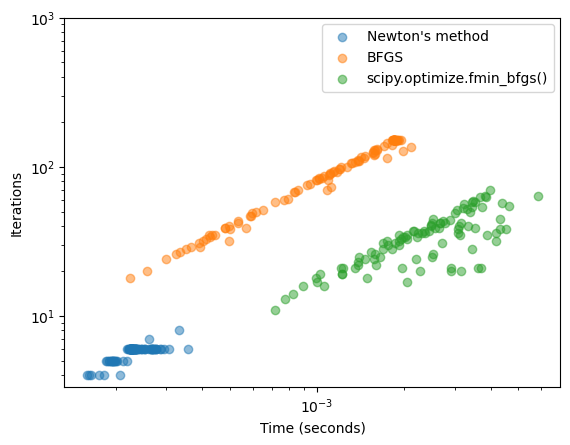

In [9]:
import warnings
np.random.seed(3)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Attempt to set non-positive ylim")
    prob3()

Newton's method converges in a handful of iterations from every start, and SciPy's BFGS (with its line search) in a few dozen. My BFGS, without a line search, needs several times as many iterations as SciPy's, and some runs stop at the cap of 150 iterations set in `prob3()`. Timings depend on the machine: all three methods run faster here than in the spec's figure, but the ordering is the same.

## The Gauss-Newton Method

### Non-linear Least Squares Problems

Least squares problems fit a line (or model parameters) to a set of data points. They arise in economics, physics, statistics and many other fields, and are unconstrained optimization problems that minimize an objective function of the form

$$f(\mathbf{x}) = \frac{1}{2}\sum_{j=1}^m r_j^2(\mathbf{x}),$$

where each $r_j : \mathbb{R}^n \to \mathbb{R}$ is smooth and $m \ge n$. Specifically, given data points $(t_1, y_1), \ldots, (t_m, y_m)$, let $\phi(\mathbf{x}, t)$ be a possible model for the data, where $\mathbf{x}$ is a vector of model parameters. The error at the $i$-th data point, the *residual*, is $r_i(\mathbf{x}) := \phi(\mathbf{x}, t_i) - y_i$, and summing the squares gives the objective above. Its first and second derivatives are

$$Df(\mathbf{x}) = J(\mathbf{x})^\mathsf{T}\mathbf{r}(\mathbf{x}), \qquad D^2f(\mathbf{x}) = J(\mathbf{x})^\mathsf{T}J(\mathbf{x}) + \sum_{j=1}^m r_j(\mathbf{x})D^2r_j(\mathbf{x}),$$

with $\mathbf{r}(\mathbf{x}) = [r_1(\mathbf{x}), \ldots, r_m(\mathbf{x})]^\mathsf{T}$ and

$$J(\mathbf{x}) = \begin{bmatrix} Dr_1(\mathbf{x}) \\ \vdots \\ Dr_m(\mathbf{x}) \end{bmatrix} \in \mathbb{R}^{m \times n}.$$

The second term of $D^2f$ involves second derivatives and can be problematic to compute. In practice it is small, either because the residuals themselves are small or because they are nearly affine near the solution. The *Gauss-Newton method* simply ignores it, making the approximation $D^2f(\mathbf{x}) \approx J(\mathbf{x})^\mathsf{T}J(\mathbf{x})$, and proceeds like Newton's method:

$$\mathbf{x}_{k+1} = \mathbf{x}_k - (J(\mathbf{x}_k)^\mathsf{T}J(\mathbf{x}_k))^{-1}J(\mathbf{x}_k)^\mathsf{T}\mathbf{r}(\mathbf{x}_k). \tag{12.8}$$

As an example, suppose data points are generated from $y = 3\sin(x/2)$ and slightly perturbed by Gaussian noise. To fit the data to the model $\phi(\mathbf{x}, t_i) = \phi(x_0, x_1, t_i) = x_0\sin(x_1t_i)$, select values for $\mathbf{x} = [x_0, x_1]^\mathsf{T}$ (we expect $x_0 \approx 3$ and $x_1 \approx 1/2$). Begin by writing functions for the proposed model, the residual vector, and the Jacobian of the residuals; by inspecting the data, an initial guess could be $\mathbf{x}_0 = (2.5, 0.6)$. The spec's code, which runs after Problem 4 below:

```python
# Generate random data for t = 0, 1, ..., 10.
>>> T = np.arange(10)
>>> y = 3*np.sin(0.5*T)+ 0.5*np.random.randn(10)     # Perturbed data.

# Define the model function and the residual (based on the data).
>>> model = lambda x, t: x[0]*np.sin(x[1]*t)        # phi(x,t)
>>> residual = lambda x: model(x, T) - y            # r(x) = phi(x,t) - y

# Define the Jacobian of the residual function, computed by hand.
>>> jac = lambda x: np.column_stack((np.sin(x[1]*t), x[0]*t*np.cos(x[1]*t)))

>>> x0 = np.array([2.5,.6])
>>> x, conv, niters = gauss_newton(jac, residual, x0, maxiter=10, tol=1e-3)

# Plot the fitted model with the observed data and the data-generating curve.
>>> dom = np.linspace(0, 10, 200)
>>> plt.plot(T, y, '*')                             # Observed data.
>>> plt.plot(dom, 3*np.sin(.5*dom), '--')           # Data-generating curve.
>>> plt.plot(dom, model(x, dom))                    # Fitted model.
>>> plt.show()
```

## Problem 4: Gauss-Newton

> **Problem 4.** Write a function that accepts a function for the proposed model $\phi(\mathbf{x})$, the model derivative $D\phi(\mathbf{x})$, a function that returns the residual vector $\mathbf{r}(\mathbf{x})$, a callable function that returns the Jacobian of the residual $D\mathbf{r}(\mathbf{x}) = J(\mathbf{x})$, a starting point $\mathbf{x}_0$, a max number of iterations `maxiter`, and a stopping tolerance `tol`. This method should implement the Gauss-Newton Method and return a list containing: the minimizing $\mathbf{x}$ value, the number of iterations performed, and if the method converged as a boolean.
>
> Test your function by using the Jacobian function, residual function, and starting point given in the example above. Compare your results to `scipy.optimize.leastsq()`.
>
> ```python
> >>> minx = opt.leastsq(func=residual, x0=np.array([2.5,.6]), Dfun=jac)
> ```

`gauss_newton()` follows the calling convention of the spec's example, `gauss_newton(jac, residual, x0, maxiter, tol)`, and returns `(x, converged, iterations)`.

In [10]:
def gauss_newton(J, r, x0, maxiter=10, tol=1e-5):
    """Solve a nonlinear least squares problem with the Gauss-Newton method.

    Parameters:
        J (function): Jacobian of the residual function. Accepts a NumPy array
            of shape (n,) and returns a NumPy array of shape (m,n).
        r (function): Residual vector function. Accepts a NumPy array of shape
            (n,) and returns an array of shape (m,).
        x0 ((n,) ndarray): The initial guess.
        maxiter (int): The maximum number of iterations to compute.
        tol (float): The stopping tolerance.

    Returns:
        ((n,) ndarray): The approximate optimizer of f.
        (bool): Whether or not the algorithm converged.
        (int): The number of iterations computed.
    """
    # Keep track of convergence and number of iterations
    converged = False
    iterations = 0
    # Loop maxiter number of times before convergence
    for i in range(maxiter):
        iterations += 1
        # Store J.T@r and J.T@J for efficiency
        Jr = J(x0).T @ r(x0)
        JJ = J(x0).T @ J(x0)
        # Equation 12.8
        x1 = x0 - la.solve(JJ, Jr)
        # Condition for convergence
        if la.norm(Jr) < tol:
            converged = True
            break
        # Update x0
        x0 = x1

    return x1, converged, iterations

The spec's example, seeded. Its `jac` uses `t`, which is undefined at that point; the data points `T` are meant, as in `residual`.

gauss_newton(): [2.9056785  0.50998358] True 6
leastsq():      [2.9056785  0.50998358]


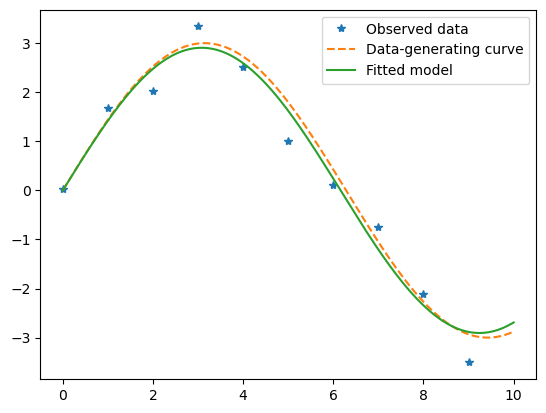

In [11]:
np.random.seed(4)
# Generate random data for t = 0, 1, ..., 10.
T = np.arange(10)
y = 3*np.sin(0.5*T)+ 0.5*np.random.randn(10)        # Perturbed data.

# Define the model function and the residual (based on the data).
model = lambda x, t: x[0]*np.sin(x[1]*t)           # phi(x,t)
residual = lambda x: model(x, T) - y               # r(x) = phi(x,t) - y

# Define the Jacobian of the residual function, computed by hand.
jac = lambda x: np.column_stack((np.sin(x[1]*T), x[0]*T*np.cos(x[1]*T)))

x0 = np.array([2.5,.6])
x, conv, niters = gauss_newton(jac, residual, x0, maxiter=10, tol=1e-3)
minx = opt.leastsq(func=residual, x0=np.array([2.5,.6]), Dfun=jac)
print("gauss_newton():", x, conv, niters)
print("leastsq():     ", minx[0])
assert conv and np.allclose(x, minx[0], atol=1e-4)

# Plot the fitted model with the observed data and the data-generating curve.
dom = np.linspace(0, 10, 200)
plt.plot(T, y, '*', label="Observed data")
plt.plot(dom, 3*np.sin(.5*dom), '--', label="Data-generating curve")
plt.plot(dom, model(x, dom), label="Fitted model")
plt.legend()
plt.show()

## Application of Non-linear Least Squares

Non-linear least squares problems can be used to analyze trends in data or to predict future events, and are ubiquitous in many academic fields as well as in industrial applications and machine learning.

## Problem 5: Fitting U.S. census data

> **Problem 5.** The file `population.npy` contains census data from the United States every ten years since 1790 for 16 decades. The first column ($t$) gives the number of decades since 1790 in the decade ($0, 1, \ldots$) and the second column ($y$) gives the population count in millions of people.
>
> By plotting the data, and with a little knowledge about population growth, it is reasonable to hypothesize an exponential model for the population:
>
> $$\phi(x_1, x_2, x_3, t) = x_1\exp(x_2(t + x_3)).$$
>
> Use the initial guess $(1.5, .4, 2.5)$ for the parameters $(x_1, x_2, x_3)$ and your Gauss Newton function or `scipy.optimize.leastsq()` to fit this model. Plot the resulting curve along with the actual data points.
>
> Unfortunately, the exponential model isn't a very good fit for the data because the population grows exponentially for only the first 8 or so decades.ᵃ Instead, consider the following logistic model.
>
> $$\phi(x_1, x_2, x_3, t) = \frac{x_1}{1 + \exp(-x_2(t + x_3))}.$$
>
> A reasonable initial guess for the parameters $(x_1, x_2, x_3)$ is $(150, .4, -15)$. Write functions for the model and the corresponding residual vector, then fit the model. Plot the data against the fitted curve (in the same plot as before). It should be a much better fit than the exponential curve.
>
> <sub>ᵃ Fitting an exponential model to only the first 8 data points results in a good model for those points (but not for later data).</sub>

In [12]:
def prob5(filename="population.npy"):
    """Load the data from the given file. Fit the data to an exponential model

        phi(x1, x2, x3, t) = x1 exp(x2(t + x3))

    and to a logistic model

        phi(x1, x2, x3, t) = x1 / (1 + exp(-x2(t + x3))).

    Plot the resulting curves along with the data points.
    """
    # Load the data and split the attributes
    data = np.load(filename)
    T = data[:,0]
    y = data[:,1]
    # Exponential model, the residual, and its Jacobian
    x0 = np.array([1.5, .4, 2.5])
    phi = lambda x, t: x[0] * np.exp(x[1]*(t + x[2]))
    residual = lambda x: phi(x, T) - y
    jac = lambda x: np.column_stack((np.exp(x[1]*(T+x[2])), \
                                    x[0]*(T+x[2])*np.exp(x[1]*(T+x[2])), \
                                    x[0]*x[1]*np.exp(x[1]*(T+x[2]))))
    # Changed: added factor=1. x1 and x3 are redundant in this model, so the
    # Jacobian is rank-deficient; with the default initial step SciPy 1.16's
    # leastsq() jumps to x = (727, 0.36, -1207), where the fitted curve
    # underflows to 0. A smaller initial step keeps the fit on track.
    m2 = leastsq(func=residual, x0=x0, Dfun=jac, factor=1)
    # Logistic model, the residual, and its Jacobian
    x1 = np.array([150, .4, -15])
    phi2 = lambda x, t: x[0] / (1 + np.exp(-x[1]*(t + x[2])))
    res2 = lambda x: phi2(x, T) - y
    jac2 = lambda x: np.column_stack((1 / (1 + np.exp(-x[1]*(T + x[2]))), \
                                     x[0]*(T+x[2])*np.exp(-x[1]*(T+x[2]))*(1+np.exp(-x[1]*(T+x[2])))**(-2) , \
                                     x[0]*x[1]*np.exp(-x[1]*(T+x[2]))*(1+np.exp(-x[1]*(T+x[2])))**(-2)))
    m4 = leastsq(func=res2, x0=x1, Dfun=jac2)
    # Plot the data and the models together
    dom = np.linspace(0, 15, 200)
    plt.plot(T, y, '*', label="Data points")
    plt.plot(dom, phi(m2[0], dom), label="Exponential model")
    plt.plot(dom, phi2(m4[0], dom), label="Logistic model")
    plt.xlabel("Time (decade)")
    plt.ylabel("Population (millions)")
    plt.legend()
    plt.show()

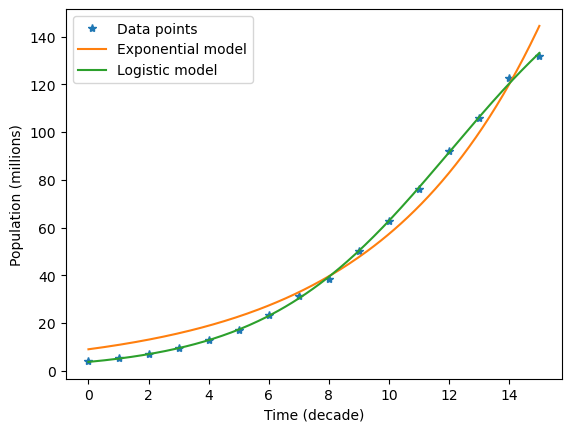

In [13]:
prob5()

Checks on the fits. The exponential model depends on $x_1$ and $x_3$ only through $x_1e^{x_2x_3}$, so its parameters are not unique and only the fitted curve can be compared: here against `scipy.optimize.curve_fit()` on the equivalent two-parameter model $ce^{x_2t}$. The logistic fit is compared with my `gauss_newton()` from Problem 4.

In [14]:
data = np.load("population.npy")
T, y = data[:,0], data[:,1]

# Exponential: the leastsq() fit (as in prob5) against curve_fit() on c*exp(x2*t).
phi = lambda x, t: x[0] * np.exp(x[1]*(t + x[2]))
jac = lambda x: np.column_stack((np.exp(x[1]*(T+x[2])),
                                 x[0]*(T+x[2])*np.exp(x[1]*(T+x[2])),
                                 x[0]*x[1]*np.exp(x[1]*(T+x[2]))))
xe = leastsq(lambda x: phi(x, T) - y, x0=np.array([1.5, .4, 2.5]), Dfun=jac, factor=1)[0]
(c, rate), _ = curve_fit(lambda t, c, rate: c*np.exp(rate*t), T, y, p0=[1.5*np.exp(1), .4])
print(f"exponential: leastsq x = {xe},  x1*exp(x2*x3) = {xe[0]*np.exp(xe[1]*xe[2]):.6f}")
print(f"             curve_fit c = {c:.6f}, x2 = {rate:.6f}")
assert np.allclose(phi(xe, T), c*np.exp(rate*T), rtol=1e-4)

# Logistic: leastsq() with the Jacobian from prob5 against gauss_newton().
phi2 = lambda x, t: x[0] / (1 + np.exp(-x[1]*(t + x[2])))
res2 = lambda x: phi2(x, T) - y
e = lambda x: np.exp(-x[1]*(T + x[2]))
jac2 = lambda x: np.column_stack((1/(1 + e(x)), x[0]*(T + x[2])*e(x)/(1 + e(x))**2, x[0]*x[1]*e(x)/(1 + e(x))**2))
xl = leastsq(func=res2, x0=np.array([150, .4, -15]), Dfun=jac2)[0]
xg, conv, niters = gauss_newton(jac2, res2, np.array([150, .4, -15]), maxiter=50, tol=1e-6)
print(f"logistic:    leastsq x = {xl},  gauss_newton x = {xg} ({niters} iterations)")
assert conv and np.allclose(xl, xg, rtol=1e-5)
print(f"residual norms: exponential {la.norm(phi(xe, T) - y):.2f}, logistic {la.norm(res2(xl)):.2f}")

exponential: leastsq x = [13.63303674  0.18474661 -2.22328345],  x1*exp(x2*x3) = 9.040839
             curve_fit c = 9.041197, x2 = 0.184744
logistic:    leastsq x = [184.76582414   0.32169312 -12.05552938],  gauss_newton x = [184.76583367   0.32169311 -12.05552974] (10 iterations)
residual norms: exponential 24.32, logistic 3.37


## Test cases: `main()`

`main()` runs the test case for one problem at a time; `"prob3"` and `"prob5"` just call `prob3()` and `prob5()`, shown above. The `.py` version ended with an `if __name__ == "__main__":` block that turned on interactive plotting and passed the problem name from the command line (`sys.argv[1]`), which a notebook doesn't need, so `main()` is called directly below.

In [15]:
# Test cases
def main(prob):
    # Problem 1
    if prob == "prob1":
        x0 = (-2,2)
        # Solve for the minimizer using problem 1 and scipy
        m1 = newton(rosen_der, rosen_hess, x0)
        m2 = fmin_bfgs(rosen, x0, disp=False, retall=True)
        # Print the results
        print(m1)
        print(m2[0], len(m2[1]))
        # Converges at i = 6

    # Problem 2
    elif prob == "prob2":
        x0 = (-2,2)
        # Solve for the minimizer using problem 2
        m = bfgs(rosen_der, x0, maxiter=150)
        # Print the results
        print(m)
        # Converges at i = 108

    # Problem 3
    elif prob == "prob3":
        prob3()

    # Problem 4
    elif prob == "prob4":
        x0 = np.array([2.5, .6])
        T = np.arange(10)
        y = 3*np.sin(0.5*T) + 0.5*np.random.randn(10)
        # Model function, residual, and its Jacobian
        model = lambda x, t: x[0]*np.sin(x[1]*t)
        residual = lambda x: model(x, T) - y
        jac = lambda x: np.column_stack((np.sin(x[1]*T), x[0]*T*np.cos(x[1]*T)))
        # Solve for the least square using problem 4 and scipy
        minx = leastsq(func=residual, x0=x0, Dfun=jac)
        m1 = gauss_newton(jac, residual, x0, maxiter=10, tol=1e-3)
        # Plot the data points, the model, and the least square
        dom = np.linspace(0, 10, 200)
        plt.plot(T, y, '*', label="Data points")
        plt.plot(dom, 3*np.sin(.5*dom), '--', label="Data-generating curve")
        plt.plot(dom, model(m1[0], dom), label="Fitted model")
        plt.xlabel("Time")
        plt.ylabel("Output")
        plt.legend()
        plt.show()
        # Print the results
        print(m1)
        print(minx)

    # Problem 5
    elif prob == "prob5":
        prob5()

In [16]:
main("prob1")
print()
main("prob2")

(array([1., 1.]), True, 6)
[0.99999575 0.99999151] 36

(array([0.86712314, 0.75157046]), False, 150)


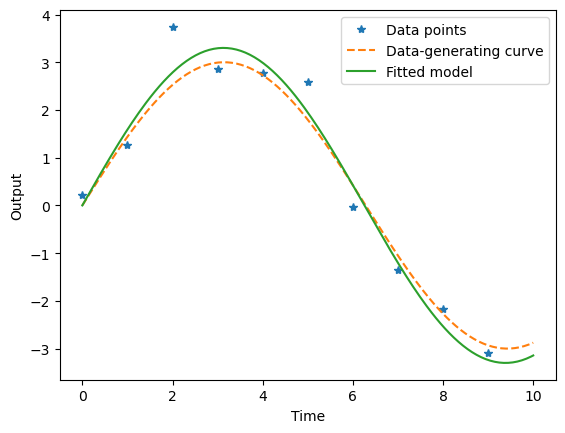

(array([3.30009544, 0.50215088]), True, 6)
(array([3.30009512, 0.50215098]), 1)


In [17]:
np.random.seed(5)
main("prob4")